In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# DATASET IMPORT & OVERVIEW

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Python 4 - Data Preprocessing Exercises/sales.csv')
df.head(50)

,order_id,name,ordered_at,price,quantity,line_total
0,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,$3.50,3,$10.50
1,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,$3.50,1,$3.50
2,10001,"""SORBET"" Raspberry",2018-01-01 12:14:54,$2.50,2,$5.00
3,10001,NaN,2018-01-01 12:14:54,$1.50,1,$1.50
4,10001,"""CONE"" Dipped Waffle Cone",2018-01-01 12:14:54,$3.50,1,$3.50
5,10002,"""SORBET"" Lychee",2018-01-01 12:23:09,$3.00,1,$3.00
6,10002,NaN,2018-01-01 12:23:09,$3.00,3,$9.00
7,10002,"""ICE CREAM"" Earl Gray",2018-01-01 12:23:09,$0.50,3,$1.50
8,10003,"""ICE CREAM"" Matcha",2018-01-01 12:49:35,$1.50,3,$4.50
9,10004,"""BEVERAGE"" Iced Coffee",2018-01-01 13:22:59,$2.50,2,$5.00


In [ ]:
# TYPE OF FEATURES AND PRESENCE OF NULL VALUES

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29922 entries, 0 to 29921
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   order_id    29922 non-null  int64 
 1   name        28434 non-null  object
 2   ordered_at  29922 non-null  object
 3   price       29922 non-null  object
 4   quantity    29922 non-null  int64 
 5   line_total  29922 non-null  object
dtypes: int64(2), object(4)
memory usage: 1.4+ MB


The only column with null values is "name"

In [ ]:
df.isnull().sum()

,0
order_id,0
name,1488
ordered_at,0
price,0
quantity,0
line_total,0


In [ ]:
df_copy = df.copy()

df_copy.head()

,order_id,name,ordered_at,price,quantity,line_total
0,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,$3.50,3,$10.50
1,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,$3.50,1,$3.50
2,10001,"""SORBET"" Raspberry",2018-01-01 12:14:54,$2.50,2,$5.00
3,10001,NaN,2018-01-01 12:14:54,$1.50,1,$1.50
4,10001,"""CONE"" Dipped Waffle Cone",2018-01-01 12:14:54,$3.50,1,$3.50


### Datatype and data fixing

In [ ]:
# CHANGE OF COLUMN NAMEs FOR "price" and "line_total"

df_copy.rename(columns={'price': 'Unit_Price_($)', 'line_total': 'Total_Price_($)'}, inplace=True)

df_copy.head()

,order_id,name,ordered_at,Unit_Price_($),quantity,Total_Price_($)
0,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,$3.50,3,$10.50
1,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,$3.50,1,$3.50
2,10001,"""SORBET"" Raspberry",2018-01-01 12:14:54,$2.50,2,$5.00
3,10001,NaN,2018-01-01 12:14:54,$1.50,1,$1.50
4,10001,"""CONE"" Dipped Waffle Cone",2018-01-01 12:14:54,$3.50,1,$3.50


In [ ]:
# CASTING OF COLUMNS "Unit_Price_($)" AND "Total_Price_($)" FROM STR TO FLOAT

str_to_float = ["Unit_Price_($)", "Total_Price_($)"]

for col in str_to_float:
  df_copy[col] = df_copy[col].str.replace('$', '', regex=False).astype(float)

df_copy.head()

,order_id,name,ordered_at,Unit_Price_($),quantity,Total_Price_($)
0,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,3.5,3,10.5
1,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,3.5,1,3.5
2,10001,"""SORBET"" Raspberry",2018-01-01 12:14:54,2.5,2,5.0
3,10001,NaN,2018-01-01 12:14:54,1.5,1,1.5
4,10001,"""CONE"" Dipped Waffle Cone",2018-01-01 12:14:54,3.5,1,3.5


In [ ]:
# FIX COLUMN "ORDERED AT" DATATYPE

df_copy["ordered_at"] = pd.to_datetime(df["ordered_at"])

In [ ]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29922 entries, 0 to 29921
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         29922 non-null  int64         
 1   name             28434 non-null  object        
 2   ordered_at       29922 non-null  datetime64[ns]
 3   Unit_Price_($)   29922 non-null  float64       
 4   quantity         29922 non-null  int64         
 5   Total_Price_($)  29922 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.4+ MB


Investigate whether each product has a unique price to determine if missing product names (NaN values) can be imputed based on their corresponding unit prices.

In [ ]:
df_copy[["name", "Unit_Price_($)"]].drop_duplicates().sort_values("Unit_Price_($)")

,name,Unit_Price_($)
2689,"""ICE CREAM"" Dark Chocolate",-4.0
3249,"""BEVERAGE"" Tea",-4.0
1595,"""CONE"" Waffle Cone",-4.0
546,"""CONE"" Cookie Cone",-4.0
1355,"""CONE"" Dipped Waffle Cone",-3.5
...,...,...
86,"""ICE CREAM"" Dark Chocolate",4.0
16,"""CONE"" Waffle Cone",4.0
62,"""BEVERAGE"" Tea",4.0
125,NaN,4.0


Many products share the same price, therefore the strategy of imputing based on the unique price cannot be implemented.

During investigation, negative prices were returned for some category, therefore i'll verify whether the total price is still positive despite a negative unit price.

In [ ]:
df_copy.drop_duplicates().sort_values("Unit_Price_($)")

,order_id,name,ordered_at,Unit_Price_($),quantity,Total_Price_($)
22272,17469,"""ICE CREAM"" Dark Chocolate",2018-06-06 04:04:26,-4.0,2,-8.0
21007,17053,"""CONE"" Cookie Cone",2018-05-28 13:51:55,-4.0,3,-12.0
20885,17011,"""ICE CREAM"" Dark Chocolate",2018-05-27 17:42:32,-4.0,1,-4.0
4095,11378,"""BEVERAGE"" Tea",2018-01-30 11:55:21,-4.0,1,-4.0
20777,16971,"""CONE"" Cookie Cone",2018-05-26 20:23:44,-4.0,2,-8.0
...,...,...,...,...,...,...
9148,13053,"""ICE CREAM"" Dark Chocolate",2018-03-06 16:05:41,4.0,3,12.0
29799,19990,"""CONE"" Cookie Cone",2018-07-28 15:11:13,4.0,3,12.0
9153,13054,"""BEVERAGE"" Tea",2018-03-06 16:14:15,4.0,3,12.0
29817,19997,"""CONE"" Waffle Cone",2018-07-28 17:40:40,4.0,3,12.0


Also total price is negative when unit price is negative. Therefore both negative unit prices and total prices will be made positive

In [ ]:
neg_to_pos = ["Unit_Price_($)", "Total_Price_($)"]

for col in neg_to_pos:
  df_copy[col] = df_copy[col].abs()

df_copy[["name", "Unit_Price_($)", "Total_Price_($)"]].drop_duplicates().sort_values("Unit_Price_($)")

,name,Unit_Price_($),Total_Price_($)
7,"""ICE CREAM"" Earl Gray",0.5,1.5
17,"""ICE CREAM"" Candied Bacon",0.5,0.5
31,"""ICE CREAM"" Earl Gray",0.5,1.0
56,"""ICE CREAM"" Candied Bacon",0.5,1.5
77,NaN,0.5,1.0
...,...,...,...
16,"""CONE"" Waffle Cone",4.0,8.0
21,"""CONE"" Waffle Cone",4.0,4.0
16835,"""CONE"" Cookie Cone",4.0,9.0
386,NaN,4.0,12.0


Both unit prices and total prices are now all positive

### Handling duplicate rows and set index

In [ ]:
df_copy[df_copy.duplicated()].shape[0]

549

Verifying a sample of duplicates by picking 5 orders

In [ ]:
# Identify all duplicated rows
duplicates = df_copy[df_copy.duplicated(keep=False)]

# Select 5 distinct orders containing duplicates
sample_ids = pd.Series(duplicates["order_id"].unique()).sample(n=min(5, duplicates["order_id"].nunique()), random_state=42)

# Display the complete selected orders
df_copy[df_copy["order_id"].isin(sample_ids)].sort_values("order_id")

,order_id,name,ordered_at,Unit_Price_($),quantity,Total_Price_($)
4763,11601,"""ICE CREAM"" Rocky Road",2018-02-04 14:36:06,3.5,1,3.5
4764,11601,"""ICE CREAM"" Wildberry",2018-02-04 14:36:06,1.5,1,1.5
4765,11601,"""ICE CREAM"" Matcha",2018-02-04 14:36:06,1.5,3,4.5
29907,11601,"""ICE CREAM"" Rocky Road",2018-02-04 14:36:06,3.5,1,3.5
29903,12456,"""CONE"" Cookie Cone",2018-02-22 10:20:27,4.0,2,8.0
7331,12456,"""CONE"" Cookie Cone",2018-02-22 10:20:27,4.0,2,8.0
8157,12739,"""ICE CREAM"" Mint Chip",2018-02-28 02:59:29,1.5,3,4.5
8158,12739,"""ICE CREAM"" Wildberry",2018-02-28 02:59:29,1.5,1,1.5
8159,12739,"""ICE CREAM"" Wildberry",2018-02-28 02:59:29,1.5,1,1.5
11994,14001,"""ICE CREAM"" Mint Chip",2018-03-25 23:53:23,1.5,2,3.0


These duplicates are clearly mistakes. The possibility that a multiple purchase of the same item may have been recorded in multiple rows is very unlikely, beacuse the purchases of multiple units of the same product are recorded in the same row by increasing the quantity. Two different procedures to record the same event cannot exist.

In [ ]:
df_copy = df_copy.drop_duplicates()

In [ ]:
df_copy['order_id'].is_unique

False

In [ ]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29373 entries, 0 to 29821
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         29373 non-null  int64         
 1   name             27892 non-null  object        
 2   ordered_at       29373 non-null  datetime64[ns]
 3   Unit_Price_($)   29373 non-null  float64       
 4   quantity         29373 non-null  int64         
 5   Total_Price_($)  29373 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.6+ MB


From 29922 to 29373 lines

### Dealing with null values

In [ ]:
df_copy.isnull().sum()

,0
order_id,0
name,1481
ordered_at,0
Unit_Price_($),0
quantity,0
Total_Price_($),0


After duplicates removal, null values decrease from 1488 to 1481: there were duplicates among nan values

In [ ]:
df_copy = df_copy.dropna()

In [ ]:
df_copy.head()

,order_id,name,ordered_at,Unit_Price_($),quantity,Total_Price_($)
0,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,3.5,3,10.5
1,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,3.5,1,3.5
2,10001,"""SORBET"" Raspberry",2018-01-01 12:14:54,2.5,2,5.0
4,10001,"""CONE"" Dipped Waffle Cone",2018-01-01 12:14:54,3.5,1,3.5
5,10002,"""SORBET"" Lychee",2018-01-01 12:23:09,3.0,1,3.0


In [ ]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27892 entries, 0 to 29821
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         27892 non-null  int64         
 1   name             27892 non-null  object        
 2   ordered_at       27892 non-null  datetime64[ns]
 3   Unit_Price_($)   27892 non-null  float64       
 4   quantity         27892 non-null  int64         
 5   Total_Price_($)  27892 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.5+ MB


From 29373 to 27892 lines

### Check for value ranges and assumptions

In [ ]:
# VERIFY WHETHER THERE EXIST Total_Price_($) cells that don't match Unit_Price_($) * quantity

df_copy[(df_copy['Unit_Price_($)'] * df_copy['quantity']) != df_copy['Total_Price_($)']].shape[0]

28

Investigating 28 totals

In [ ]:
df_copy[(df_copy['Unit_Price_($)'] * df_copy['quantity']) != df_copy['Total_Price_($)']]

,order_id,name,ordered_at,Unit_Price_($),quantity,Total_Price_($)
68,10022,"""SORBET"" Lychee",2018-01-02 00:38:37,3.0,2,5.0
295,10097,"""BEVERAGE"" Iced Coffee",2018-01-03 12:20:11,2.5,2,6.0
3203,11071,"""ICE CREAM"" Wildberry",2018-01-23 13:26:07,1.5,2,2.0
6475,12172,"""BEVERAGE"" Tea",2018-02-16 07:19:04,4.0,3,11.0
7472,12504,"""ICE CREAM"" Candied Bacon",2018-02-23 06:55:04,0.5,2,0.0
8781,12937,"""BEVERAGE"" Tea",2018-03-04 06:52:12,4.0,2,9.0
9431,13140,"""CONE"" Brownie Cone",2018-03-08 06:00:34,3.0,1,2.0
10034,13343,"""SORBET"" Raspberry",2018-03-12 10:18:34,2.5,1,3.5
11720,13909,"""ICE CREAM"" Maple Brown Sugar",2018-03-24 03:38:05,2.0,2,3.0
11773,13929,"""BEVERAGE"" Iced Coffee",2018-03-24 13:53:45,2.5,1,1.5


Clearly typos or calculation errors. They will be fixed

In [ ]:
# FIXING THE WRONG TOTALS IN COLUMN "Total_Price_($)"

# Boolean mask --> result = Series of boolean values:
# TRUE if Total_Price_($) * quantity != Total_Price_($)
# FALSE otherwise
mask = (df_copy['Unit_Price_($)'] * df_copy['quantity']) != df_copy['Total_Price_($)']

# Select in df_copy the rows with index = index of rows in booloean mask that returned TRUE, to fix them with correct total
df_copy.loc[mask, 'Total_Price_($)'] = (df_copy.loc[mask, 'Unit_Price_($)'] * df_copy.loc[mask, 'quantity'])

In [ ]:
df_copy[(df_copy['Unit_Price_($)'] * df_copy['quantity']) != df_copy['Total_Price_($)']].shape[0]

0

In [ ]:
# CHECK OF SUMMARY STATISTICS

df_copy.describe()

,order_id,ordered_at,Unit_Price_($),quantity,Total_Price_($)
count,27892.000000,27892,27892.000000,27892.000000,27892.000000
mean,14992.479026,2018-04-15 11:01:45.670120704,2.512333,2.001040,5.031765
min,10000.000000,2018-01-01 11:30:00,0.500000,1.000000,0.500000
25%,12496.000000,2018-02-23 01:31:58,1.500000,1.000000,2.500000
50%,14972.000000,2018-04-14 14:49:18,2.500000,2.000000,4.500000
75%,17508.250000,2018-06-07 01:13:10.249999872,3.500000,3.000000,7.500000
max,19999.000000,2018-07-28 18:51:57,4.000000,3.000000,12.000000
std,2889.913777,NaN,1.059432,0.819061,3.087248


## Analysis

### Create a new column named "category"

In [ ]:
# CREATE A NEW COLUMN NAMED "CATEGORY"

# Extract product category from the original name column and create a new column "category"
df_copy["category"] = df_copy["name"].str.extract(r'^"([^"]+)"', expand=False)

df_copy.head()

,order_id,name,ordered_at,Unit_Price_($),quantity,Total_Price_($),category
0,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,3.5,3,10.5,ICE CREAM
1,10000,"""ICE CREAM"" Peanut Fudge",2018-01-01 11:30:00,3.5,1,3.5,ICE CREAM
2,10001,"""SORBET"" Raspberry",2018-01-01 12:14:54,2.5,2,5.0,SORBET
4,10001,"""CONE"" Dipped Waffle Cone",2018-01-01 12:14:54,3.5,1,3.5,CONE
5,10002,"""SORBET"" Lychee",2018-01-01 12:23:09,3.0,1,3.0,SORBET


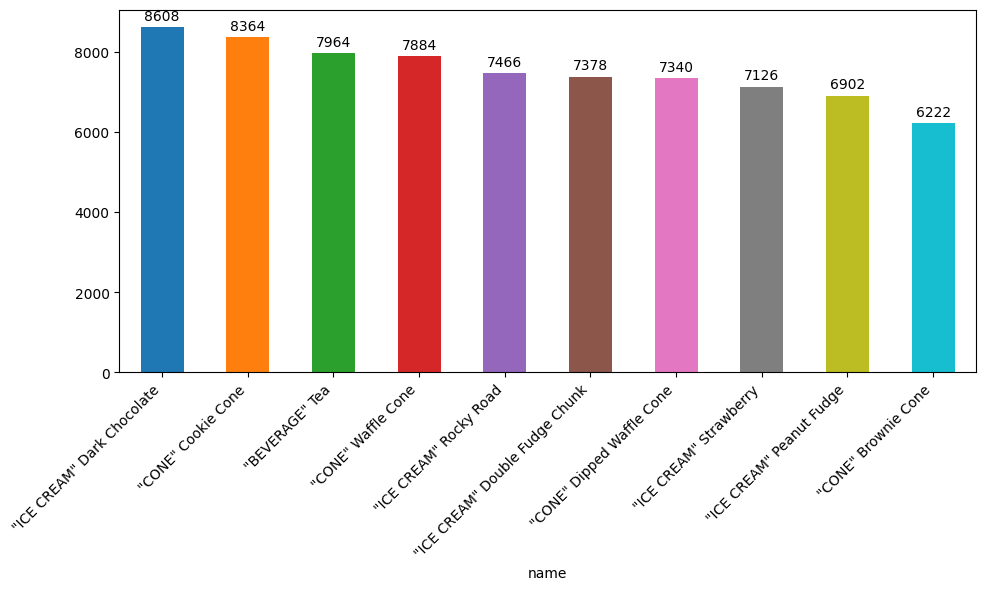

In [ ]:
# BAR GRAPH OF TOP 10 PRODUCTS

top_10_products = (df_copy.groupby("name")["Total_Price_($)"].sum().sort_values(ascending=False).head(10))

graph_10_prods = top_10_products.plot(kind="bar", color=sns.color_palette("tab10", n_colors=len(top_10_products)), figsize=(10, 6))

# Rotate x-axis labels
plt.xticks(rotation=45, ha="right")

# Display values above bars
graph_10_prods.bar_label(graph_10_prods.containers[0], fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

Within the top 3 we find 3 different categories of product.

Top 3 flavours of ICE CREAM are: Dark chocolate, Rocky Road and Double Fudge Chunk

No other products of BEVERAGE are in top 10.

SORBET and MISC are out of the top 10

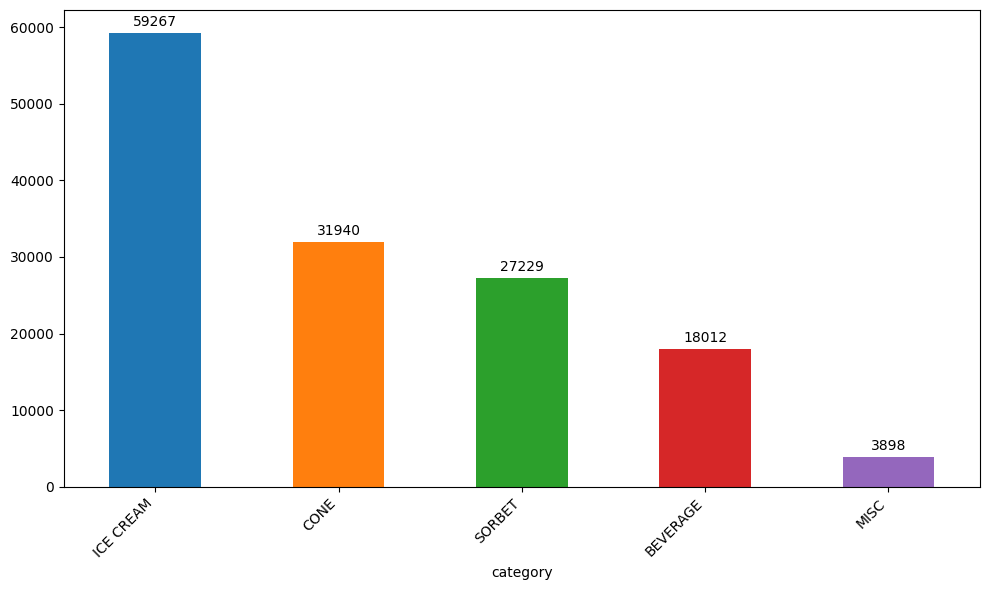

In [ ]:
# BAR GRAPH CATEGORIES

categories_ranking = (df_copy.groupby("category")["Total_Price_($)"].sum().sort_values(ascending=False).head(10))

graph_categs = categories_ranking.plot(kind="bar", color=sns.color_palette("tab10", n_colors=len(top_10_products)), figsize=(10, 6))

# Rotate x-axis labels
plt.xticks(rotation=45, ha="right")

# Display values above bars
graph_categs.bar_label(graph_categs.containers[0], fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

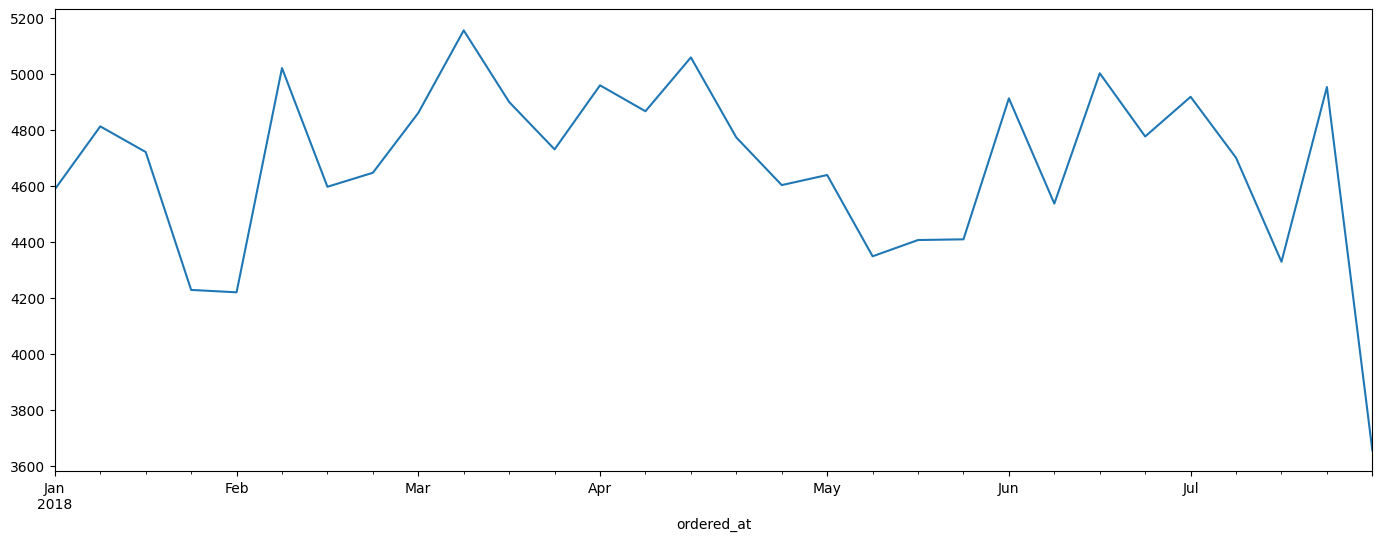

In [ ]:
# LINECHART

f, ax = plt.subplots(figsize=(17, 6))
df_copy.resample('W', on='ordered_at')['Total_Price_($)'].sum().plot()
plt.show()